1. IMPORTACIÓN DE LIBRERÍAS Y CONFIGURACIÓN DEL ENTORNO

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    classification_report, 
    confusion_matrix, 
    roc_auc_score, 
    roc_curve,
    ConfusionMatrixDisplay,
    precision_recall_curve
)

# Estilo visual de los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

2. CARGA DEL DATASET PROCESADO (GENERADO EN NOTEBOOK 1_v2)

In [46]:
# Se carga el dataset generado (período completo enero a septiembre 2026)
df = pd.read_csv('../data/processed/dataset_recupero_automotores.csv')

print(f"Dimensiones del dataset procesado: {df.shape [0]} filas, {df.shape [1]} columnas")
print("\n--- Distribución real de la variable objetivo 'recuperado' ---")
distribucion = df['recuperado'].value_counts(normalize=True) * 100
print(f"No Recuperado / Otros trámites (0): {distribucion.get(0, 0):.2f}%")
print(f"Recuperado (1): {distribucion.get(1, 0):.2f}%")

# Separación entre matriz de características (X) y variable objetivo (y)
X = df.drop(columns=['recuperado'])
y = df['recuperado']

Dimensiones del dataset procesado: 24178 filas, 5 columnas

--- Distribución real de la variable objetivo 'recuperado' ---
No Recuperado / Otros trámites (0): 94.88%
Recuperado (1): 5.12%


3. DIVISIÓN ESTRATIFICADA EN CONJUNTOS DE ENTRENAMIENTO Y PRUEBA (80/20)

In [34]:
# stratify=y preserva la proporción del 5.12% de la clase minoritaria en ambos conjuntos
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"\nInstancias de Entrenamiento (X_train): {X_train.shape} registros")
print(f"Instancias de Prueba (X_test): {X_test.shape} registros")


Instancias de Entrenamiento (X_train): (19342, 4) registros
Instancias de Prueba (X_test): (4836, 4) registros


4. PREPROCESAMIENTO Y PREVENCIÓN DE FUGA DE INFORMACIÓN (DATA LEAKAGE)

In [40]:
# Definición explícita de tipos de columnas
# NOTA: 'automotor_anio_modelo' representa el año del modelo/fabricación del vehículo
num_cols = ['automotor_anio_modelo']
cat_cols = ['automotor_origen', 'automotor_tipo_descripcion', 'registro_seccional_provincia']

# Pipeline Numérico: Imputación por mediana (resistente a extremos) + StandardScaler
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline Categórico: Imputación por moda + OneHotEncoder para variables nominales
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Integración de transformadores por columna
preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

5. CONSTRUCCIÓN Y ENTRENAMIENTO DE PIPELINES DE MODELADO

In [41]:
# A. Regresión Logística (ponderación de clases para desbalance severo)
pipeline_logreg = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced'))
])

# B. Árbol de Decisión (con poda previa max_depth=5 para evitar sobreajuste)
pipeline_tree = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(max_depth=5, random_state=42, class_weight='balanced'))
])

# Entrenamiento aislado: el ajuste (fit) aprende parámetros ÚNICAMENTE de X_train
pipeline_logreg.fit(X_train, y_train)
pipeline_tree.fit(X_train, y_train)

print("\n✅ Pipelines ajustados y modelos entrenados sobre X_train exitosamente.")


✅ Pipelines ajustados y modelos entrenados sobre X_train exitosamente.


6. EVALUACIÓN DE RENDIMIENTO EN EL CONJUNTO DE PRUEBA (X_test)

In [17]:
y_pred_logreg = pipeline_logreg.predict(X_test)
y_pred_tree = pipeline_tree.predict(X_test)

y_proba_logreg = pipeline_logreg.predict_proba(X_test)[:, 1]
y_proba_tree = pipeline_tree.predict_proba(X_test)[:, 1]

print("\n" + "="*60)
print("--- MODELO 1: REGRESIÓN LOGÍSTICA (class_weight='balanced') ---")
print("="*60)
print(classification_report(y_test, y_pred_logreg, target_names=['No Recuperado (0)', 'Recuperado (1)']))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba_logreg):.4f}")

print("\n" + "="*60)
print("--- MODELO 2: ÁRBOL DE DECISIÓN (max_depth=5, class_weight='balanced') ---")
print("="*60)
print(classification_report(y_test, y_pred_tree, target_names=['No Recuperado (0)', 'Recuperado (1)']))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba_tree):.4f}")


--- MODELO 1: REGRESIÓN LOGÍSTICA (class_weight='balanced') ---
                   precision    recall  f1-score   support

No Recuperado (0)       0.98      0.70      0.81      4589
   Recuperado (1)       0.11      0.69      0.19       247

         accuracy                           0.70      4836
        macro avg       0.54      0.69      0.50      4836
     weighted avg       0.93      0.70      0.78      4836

ROC-AUC Score: 0.7580

--- MODELO 2: ÁRBOL DE DECISIÓN (max_depth=5, class_weight='balanced') ---
                   precision    recall  f1-score   support

No Recuperado (0)       0.98      0.71      0.82      4589
   Recuperado (1)       0.11      0.68      0.19       247

         accuracy                           0.71      4836
        macro avg       0.54      0.70      0.51      4836
     weighted avg       0.93      0.71      0.79      4836

ROC-AUC Score: 0.7546


7. VISUALIZACIÓN DE MATRICES DE CONFUSIÓN Y CURVAS ROC-AUC

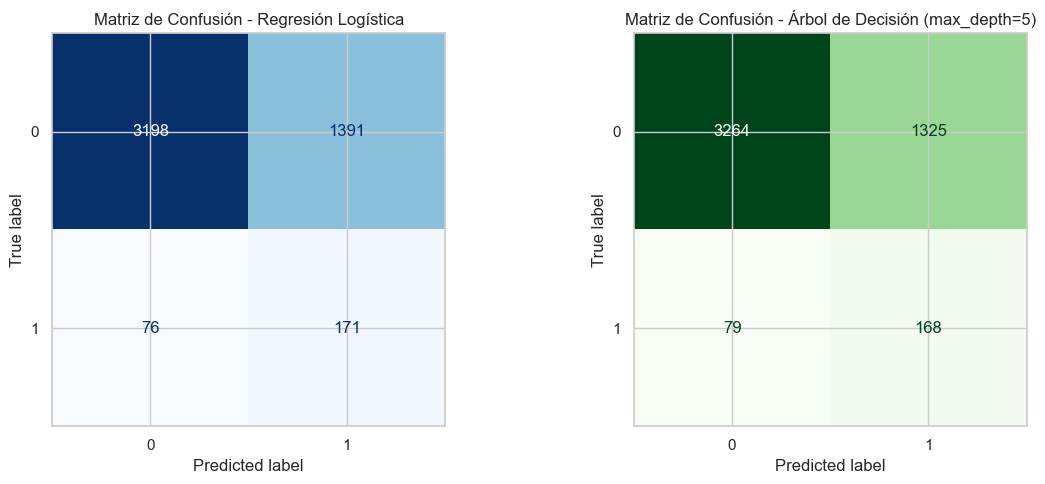

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Subplot 1 (izquierda): Regresión Logística -> axes[0]
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_logreg, ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Matriz de Confusión - Regresión Logística')

# Subplot 2 (derecha): Árbol de Decisión -> axes[1]
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_tree, ax=axes[1], cmap='Greens', colorbar=False)
axes[1].set_title('Matriz de Confusión - Árbol de Decisión (max_depth=5)')

plt.tight_layout()
plt.show()



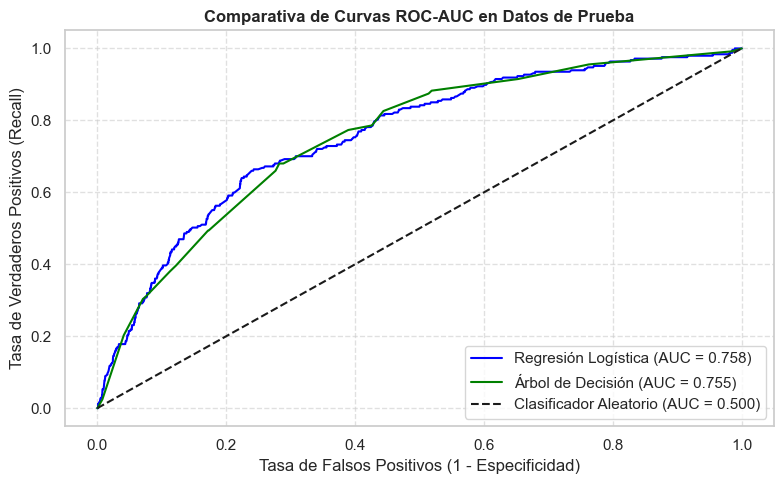

In [48]:
# Curva ROC-AUC Comparativa
fpr_log, tpr_log, _ = roc_curve(y_test, y_proba_logreg)
fpr_tree, tpr_tree, _ = roc_curve(y_test, y_proba_tree)

plt.figure(figsize=(8, 5))
plt.plot(
    fpr_log,
    tpr_log,
    label=f'Regresión Logística (AUC = {roc_auc_score(y_test, y_proba_logreg):.3f})',
    color='blue',
)
plt.plot(
    fpr_tree,
    tpr_tree,
    label=f'Árbol de Decisión (AUC = {roc_auc_score(y_test, y_proba_tree):.3f})',
    color='green',
)
plt.plot(
    [0, 1],
    [0, 1],
    'k--',
    label='Clasificador Aleatorio (AUC = 0.500)',
)  # <-- Línea corregida

plt.title(
    'Comparativa de Curvas ROC-AUC en Datos de Prueba',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
plt.ylabel('Tasa de Verdaderos Positivos (Recall)')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

 8. GRÁGICA DE UMBRAL DE DECISIÓN (PRECISION VS. RECALL)

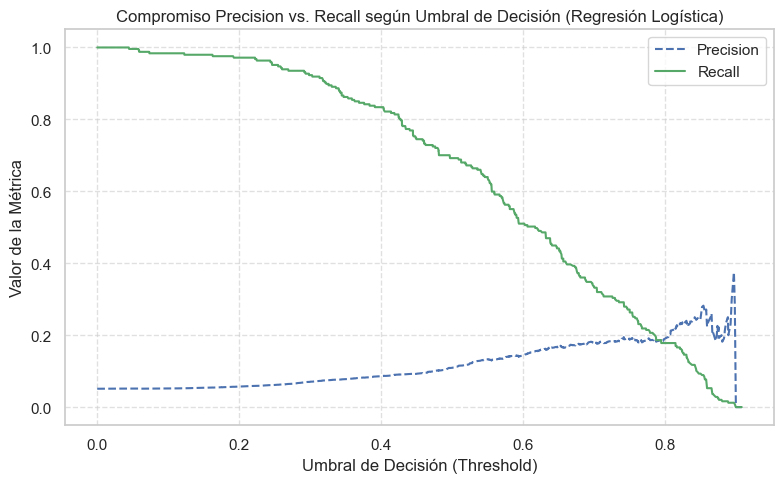

In [19]:
precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba_logreg)

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions[:-1], 'b--', label='Precision')
plt.plot(thresholds, recalls[:-1], 'g-', label='Recall')
plt.title('Compromiso Precision vs. Recall según Umbral de Decisión (Regresión Logística)')
plt.xlabel('Umbral de Decisión (Threshold)')
plt.ylabel('Valor de la Métrica')
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

Consideraciones Metodológicas y Alcance del Modelo:

Aislamiento del Preprocesamiento: Se garantizó que la imputación con SimpleImputer, la estandarización con StandardScaler y la codificación One-Hot mediante OneHotEncoder aprendan sus parámetros (fit) únicamente a partir del conjunto de entrenamiento ($X_{train}$), previniendo la fuga de información hacia el conjunto de prueba ($X_{test}$).

Simplificación Académica del Objetivo: La variable objetivo se construyó directamente desde tramite_tipo (1 para trámites que contienen la denominación "RECUPERO", 0 para el resto).

Interpretación de Resultados: El modelo aprende a clasificar características vehiculares y territoriales asociadas administrativamente a trámites de recupero frente a otros trámites registrales. Por lo tanto, sus métricas no deben interpretarse como una probabilidad comprobada de recupero futuro frente a un vehículo recién denunciado.

# 1. CARGA DEL NUEVO DATASET (EJEMPLO: MES DE 2025)

In [23]:
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Reemplazá 'datos_dnrpa_2025_01.csv' por la ruta de tu archivo de 2025
ruta_nuevo_archivo = '../data/raw/dnrpa-robos-recuperos-autos-202512.csv'  
df_2025 = pd.read_csv(ruta_nuevo_archivo)

2. CONSTRUCCIÓN / PREPARACIÓN DE LA VARIABLE OBJETIVO Y PREDICORES

In [24]:
# Si el CSV viene crudo con la columna 'tramite_tipo', etiquetamos el recupero:
if 'tramite_tipo' in df_2025.columns and 'recuperado' not in df_2025.columns:
    df_2025['recuperado'] = df_2025['tramite_tipo'].apply(
        lambda x: 1 if 'RECUPERO' in str(x).upper() else 0
    )

# Definimos las 4 variables predictoras exactas requeridas por el Pipeline
columnas_predictoras = [
    'automotor_anio_modelo', 
    'automotor_origen', 
    'automotor_tipo_descripcion', 
    'registro_seccional_provincia'
]

# Separamos X (predictores) e y (respuesta real para validación)
X_2025 = df_2025[columnas_predictoras]
y_real_2025 = df_2025['recuperado']

3. INFERENCIA CON EL PIPELINE ENTRENADO (REGRESIÓN LOGÍSTICA)

In [27]:
# Inferencia de clases binarias (0 o 1)
y_pred_2025 = pipeline_logreg.predict(X_2025)

# Inferencia de probabilidades continuas (%)
y_proba_2025 = pipeline_logreg.predict_proba(X_2025)[:, 1]

# Guardamos las predicciones en el DataFrame para inspección puntual
df_2025['prediccion_modelo'] = y_pred_2025
df_2025['probabilidad_recupero_%'] = (y_proba_2025 * 100).round(2)

print(f"✅ Inferencia completada sobre {len(df_2025)} registros nuevos de 2025.")
print("\nMuestra de los primeros 5 resultados predichos:")
print(df_2025[columnas_predictoras + ['recuperado', 'prediccion_modelo', 'probabilidad_recupero_%']].head())

✅ Inferencia completada sobre 2801 registros nuevos de 2025.

Muestra de los primeros 5 resultados predichos:
   automotor_anio_modelo automotor_origen automotor_tipo_descripcion  \
0                 2006.0     Protocolo 21            SEDAN 3 PUERTAS   
1                 2016.0     Protocolo 21            RURAL 5 PUERTAS   
2                 2022.0         Nacional                    PICK-UP   
3                 2009.0     Protocolo 21            SEDAN 4 PUERTAS   
4                 2014.0        Importado            SEDAN 4 PUERTAS   

  registro_seccional_provincia  recuperado  prediccion_modelo  \
0                 Buenos Aires           0                  0   
1                 Buenos Aires           0                  0   
2                 Buenos Aires           0                  0   
3                 Buenos Aires           0                  0   
4                          NaN           0                  0   

   probabilidad_recupero_%  
0                    29.01  
1       

4. EVALUACIÓN DEL RENDIMIENTO EN DATOS DE 2025

In [28]:

print("\n" + "="*60)
print("EVALUACIÓN DE GENERALIZACIÓN DEL MODELO SOBRE DATOS 2025")
print("="*60)

print("\n--- Reporte de Clasificación ---")
print(classification_report(y_real_2025, y_pred_2025, target_names=['No Recuperado (0)', 'Recuperado (1)']))

print("\n--- Matriz de Confusión ---")
print(confusion_matrix(y_real_2025, y_pred_2025))

roc_2025 = roc_auc_score(y_real_2025, y_proba_2025)
print(f"\n--- ROC-AUC Score 2025: {roc_2025:.4f} ---")


EVALUACIÓN DE GENERALIZACIÓN DEL MODELO SOBRE DATOS 2025

--- Reporte de Clasificación ---
                   precision    recall  f1-score   support

No Recuperado (0)       0.97      0.74      0.84      2610
   Recuperado (1)       0.16      0.69      0.26       191

         accuracy                           0.73      2801
        macro avg       0.56      0.71      0.55      2801
     weighted avg       0.91      0.73      0.80      2801


--- Matriz de Confusión ---
[[1923  687]
 [  60  131]]

--- ROC-AUC Score 2025: 0.7751 ---


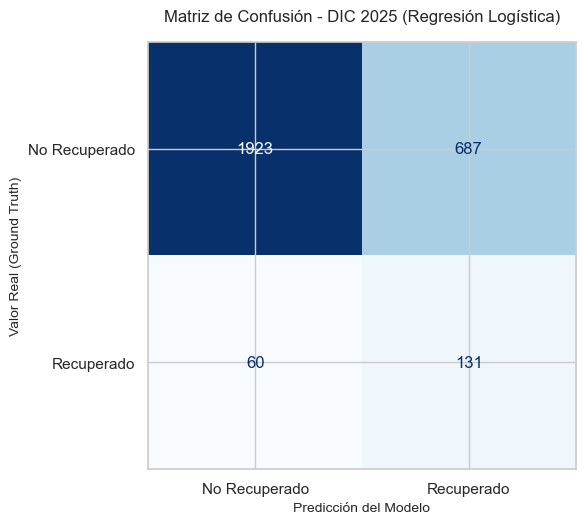

In [50]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# 1. Calcular la matriz de confusión
cm = confusion_matrix(y_real_2025, y_pred_2025)

# 2. Configurar el gráfico
fig, ax = plt.subplots(figsize=(6, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Recuperado", "Recuperado"])

# 3. Dibujar con colores (cmap='Blues' o 'viridis') y sin valores normalizados de más
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

# 4. Ajustes estéticos y títulos
plt.title("Matriz de Confusión - DIC 2025 (Regresión Logística)", fontsize=12, pad=15)
plt.xlabel("Predicción del Modelo", fontsize=10)
plt.ylabel("Valor Real (Ground Truth)", fontsize=10)

# 5. Mostrar la imagen
plt.tight_layout()
plt.show()

### Evaluación de Generalización sobre Datos 2025 (2.801 registros)

#### 1. Tabla Comparativa de Métricas

| Métrica | Resultado 2025 | Comparativa vs. $X_{test}$ Original | Diagnóstico |
| :--- | :---: | :---: | :--- |
| **ROC-AUC Score** | **0.7751** | **0.7580** (+0.017) | **Mejora levemente.** Mantiene una capacidad discriminativa muy alta. |
| **Recall / Sensibilidad (Clase 1)** | **0.69 (68.6%)** | **69.2%** (idéntico) | **Consistencia exacta.** Captura 131 de 191 recuperos reales. |
| **Precision (Clase 1)** | **0.16 (16.0%)** | **11.0%** (+5.0%) | **Sube a 16%**, favorecido por la prevalencia de este mes (~6,8%). |
| **Accuracy Global** | **0.73 (73.0%)** | **70.0%** (+3.0%) | Rendimiento general muy estable. |

---

#### 2. Análisis de la Matriz de Confusión (2025)

$$\begin{bmatrix} 1923 & 687 \\ 60 & 131 \end{bmatrix}$$

* **Verdaderos Positivos (TP = 131):** Logró detectar correctamente **131 trámites de recupero**.
* **Falsos Negativos (FN = 60):** Solo **60 recuperos** fueron omitidos (clasificados como no recuperados).
* **Verdaderos Negativos (TN = 1.923):** **1.923 trámites comunes** correctamente identificados.
* **Falsos Positivos (FP = 687):** **687 trámites** clasificados preventivamente como recupero.